In [5]:
import pandas as pd
PATH = "/kaggle/input/competitions/playground-series-s5e1/"
train = pd.read_csv(PATH + "train.csv", parse_dates=["date"])
test  = pd.read_csv(PATH + "test.csv",  parse_dates=["date"])
train.head(10)

,id,date,country,store,product,num_sold
0,0,2010-01-01,Canada,Discount Stickers,Holographic Goose,NaN
1,1,2010-01-01,Canada,Discount Stickers,Kaggle,973.0
2,2,2010-01-01,Canada,Discount Stickers,Kaggle Tiers,906.0
3,3,2010-01-01,Canada,Discount Stickers,Kerneler,423.0
4,4,2010-01-01,Canada,Discount Stickers,Kerneler Dark Mode,491.0
5,5,2010-01-01,Canada,Stickers for Less,Holographic Goose,300.0
6,6,2010-01-01,Canada,Stickers for Less,Kaggle,1837.0
7,7,2010-01-01,Canada,Stickers for Less,Kaggle Tiers,1659.0
8,8,2010-01-01,Canada,Stickers for Less,Kerneler,807.0
9,9,2010-01-01,Canada,Stickers for Less,Kerneler Dark Mode,940.0


In [6]:
test.head(10)

,id,date,country,store,product
0,230130,2017-01-01,Canada,Discount Stickers,Holographic Goose
1,230131,2017-01-01,Canada,Discount Stickers,Kaggle
2,230132,2017-01-01,Canada,Discount Stickers,Kaggle Tiers
3,230133,2017-01-01,Canada,Discount Stickers,Kerneler
4,230134,2017-01-01,Canada,Discount Stickers,Kerneler Dark Mode
5,230135,2017-01-01,Canada,Stickers for Less,Holographic Goose
6,230136,2017-01-01,Canada,Stickers for Less,Kaggle
7,230137,2017-01-01,Canada,Stickers for Less,Kaggle Tiers
8,230138,2017-01-01,Canada,Stickers for Less,Kerneler
9,230139,2017-01-01,Canada,Stickers for Less,Kerneler Dark Mode


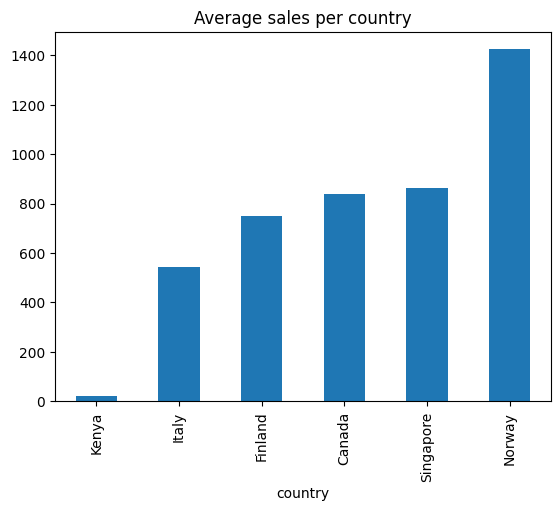

In [7]:
# Average sales per country
train.groupby("country")["num_sold"].mean().sort_values().plot(kind="bar", title="Average sales per country");

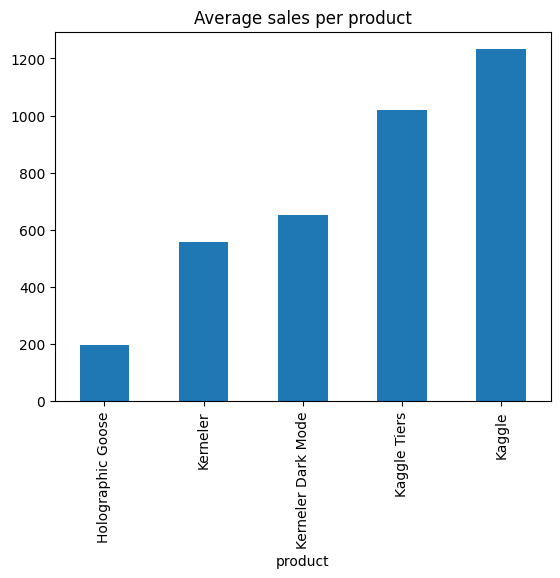

In [8]:
# Does product matter?
train.groupby("product")["num_sold"].mean().sort_values().plot(kind="bar", title="Average sales per product");

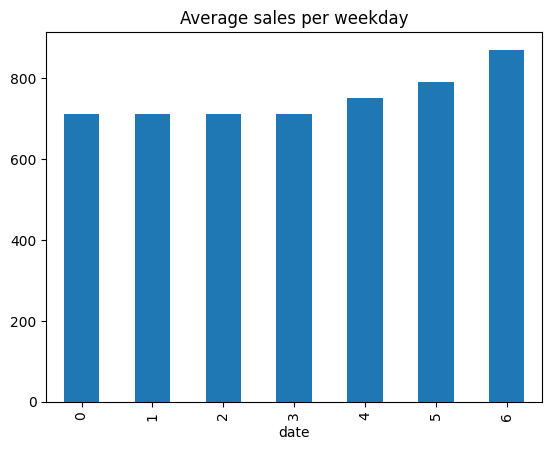

In [9]:
# Average sales per weekday (0 = Monday, 6 = Sunday)
train.groupby(train["date"].dt.dayofweek)["num_sold"].mean().plot(kind="bar", title="Average sales per weekday");

In [10]:
train = train.dropna(subset=["num_sold"])   # we drop rows with no answer

def prepare(df):
    df = df.copy()
    df["year"]      = df["date"].dt.year        # we split the date, add as labels
    df["month"]     = df["date"].dt.month
    df["weekday"]   = df["date"].dt.dayofweek
    df["dayofyear"] = df["date"].dt.dayofyear
    for c in ["country", "store", "product"]:   # we add the other labels
        df[c] = df[c].astype("category")
    return df

train = prepare(train)
test  = prepare(test)

FEATURES = ["country", "store", "product", "year", "month", "weekday", "dayofyear"]
train[FEATURES + ["num_sold"]].head()

,country,store,product,year,month,weekday,dayofyear,num_sold
1,Canada,Discount Stickers,Kaggle,2010,1,4,1,973.0
2,Canada,Discount Stickers,Kaggle Tiers,2010,1,4,1,906.0
3,Canada,Discount Stickers,Kerneler,2010,1,4,1,423.0
4,Canada,Discount Stickers,Kerneler Dark Mode,2010,1,4,1,491.0
5,Canada,Stickers for Less,Holographic Goose,2010,1,4,1,300.0


In [ ]:
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_percentage_error as mape

# Train on previous years, make it into log for prediction accuracy
final = lgb.LGBMRegressor(n_estimators=1000, learning_rate=0.05, verbose=-1)
final.fit(train[FEATURES], np.log1p(train["num_sold"]))

# Guess 2017–2019 and convert back from log
test["num_sold"] = np.expm1(final.predict(test[FEATURES]))

# Save in Kaggle format
test[["id", "num_sold"]].to_csv("submission.csv", index=False)
print(test[["id", "num_sold"]].shape)
test[["id", "num_sold"]].head()